# Data Cleaning

In [23]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns


In [24]:
data = pd.read_csv('/Users/admin/Documents/ML Engineer/Practice/housing/housing.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


## Missing Values

In [25]:
# Count missing value 

missing_values = data.isnull().sum()

percentage_missing = round((missing_values / len(data)) * 100, 3)

missing_data_info = pd.DataFrame({
    'column_name': data.columns,
    'missing_value': missing_values,
    'percentage_missing': percentage_missing
})

missing_data_info

,column_name,missing_value,percentage_missing
longitude,longitude,0,0.000
latitude,latitude,0,0.000
housing_median_age,housing_median_age,0,0.000
total_rooms,total_rooms,0,0.000
total_bedrooms,total_bedrooms,207,1.003
population,population,0,0.000
households,households,0,0.000
median_income,median_income,0,0.000
median_house_value,median_house_value,0,0.000
ocean_proximity,ocean_proximity,0,0.000


In [26]:
# Find rows of missing values 

data[data.isnull().any(axis=1)]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
290,-122.16,37.77,47.0,1256.0,NaN,570.0,218.0,4.3750,161900.0,NEAR BAY
341,-122.17,37.75,38.0,992.0,NaN,732.0,259.0,1.6196,85100.0,NEAR BAY
538,-122.28,37.78,29.0,5154.0,NaN,3741.0,1273.0,2.5762,173400.0,NEAR BAY
563,-122.24,37.75,45.0,891.0,NaN,384.0,146.0,4.9489,247100.0,NEAR BAY
696,-122.10,37.69,41.0,746.0,NaN,387.0,161.0,3.9063,178400.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20267,-119.19,34.20,18.0,3620.0,NaN,3171.0,779.0,3.3409,220500.0,NEAR OCEAN
20268,-119.18,34.19,19.0,2393.0,NaN,1938.0,762.0,1.6953,167400.0,NEAR OCEAN
20372,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,410700.0,<1H OCEAN
20460,-118.75,34.29,17.0,5512.0,NaN,2734.0,814.0,6.6073,258100.0,<1H OCEAN


In [27]:
# Handle missing value 

df = data.copy()
median_of_col = df['total_bedrooms'].median()
df['total_bedrooms'] = df['total_bedrooms'].fillna(median_of_col)

## Duplicates

In [28]:
# Cek apakah ada duplikat (True / False)
data.duplicated().any()

False

In [29]:
# Jika ada di baris apa dan kolom apa
data[data.duplicated()]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity


In [30]:
# Hitung jumlah nilai duplikat
data.duplicated().sum()

0

In [31]:
# Handle nilai duplikat
data = data.drop_duplicates()

## Outlier

### Visualize Numeric Data for Outlier Detections

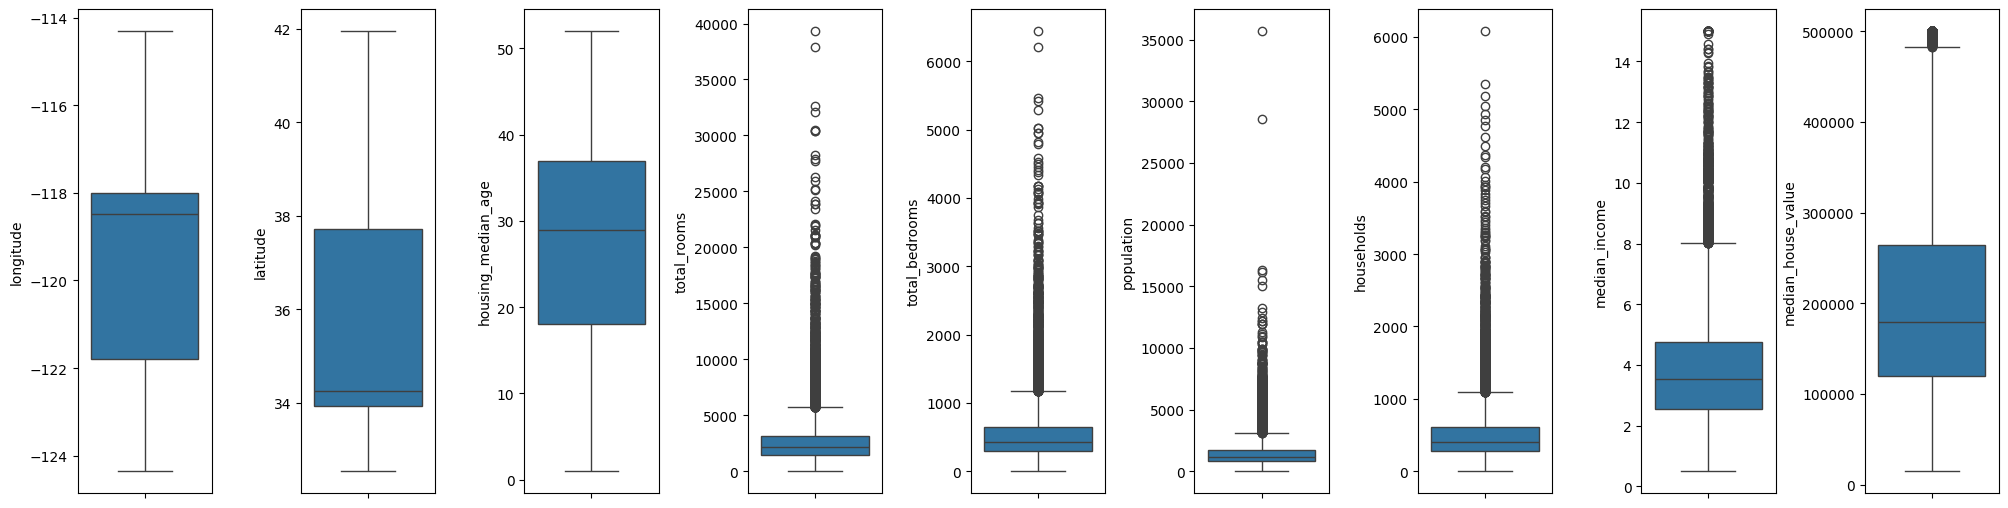

In [32]:
numeric_columns = data.select_dtypes(include=['int', 'float']).columns

fig, axs = plt.subplots(ncols=len(numeric_columns), figsize=(20,5))
for i, column in enumerate(numeric_columns):
    sns.boxplot(y=column, data=data, ax=axs[i], whis=1.5)

plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)
plt.show()
    

### IQR

In [33]:
Q1 = data[numeric_columns].quantile(0.25)
Q3 = data[numeric_columns].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

### Z-Score

In [34]:
from scipy.stats import zscore 
import numpy as np

z_scores = np.abs(zscore(data[numeric_columns]))
outliers_z = data[(z_scores > 3).any(axis=1)]
print(outliers_z)

       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
95       -122.26     37.80                36.0       5329.0          2477.0   
104      -122.26     37.81                34.0       5871.0          1914.0   
116      -122.25     37.83                28.0       5022.0          1750.0   
131      -122.19     37.84                18.0       1617.0           210.0   
283      -122.16     37.79                22.0      12842.0          2048.0   
...          ...       ...                 ...          ...             ...   
20530    -121.76     38.57                11.0      15018.0          3008.0   
20543    -121.74     38.55                33.0       6861.0          1820.0   
20544    -121.76     38.55                23.0       8800.0          1857.0   
20563    -121.75     38.67                 9.0      12139.0          2640.0   
20629    -121.39     39.12                28.0      10035.0          1856.0   

       population  households  median_income  media

### Find and Count Outlier

In [35]:
outlier_mask = pd.Series(False, index=data.index)

for col in numeric_columns:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    mask = (data[col] < lower) | (data[col] > upper)
    outlier_mask = outlier_mask | mask

outlier_rows = data[outlier_mask]
outlier_rows

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
89,-122.27,37.80,52.0,249.0,78.0,396.0,85.0,1.2434,500001.0,NEAR BAY
95,-122.26,37.80,36.0,5329.0,2477.0,3469.0,2323.0,2.0096,130000.0,NEAR BAY
96,-122.26,37.82,31.0,4596.0,1331.0,2048.0,1180.0,2.8345,183800.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20544,-121.76,38.55,23.0,8800.0,1857.0,6330.0,1832.0,2.0650,219400.0,INLAND
20563,-121.75,38.67,9.0,12139.0,2640.0,6837.0,2358.0,3.1250,132500.0,INLAND
20567,-121.79,38.66,15.0,6809.0,1052.0,3060.0,1060.0,5.3064,165000.0,INLAND
20604,-121.54,39.12,17.0,4251.0,899.0,3265.0,934.0,2.3496,65000.0,INLAND


### Drop Outlier

In [ ]:
# Cara pertama

numeric_columns = data.select_dtypes(include=['int', 'float'])

for col in numeric_columns:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)

    iqr = q3 - q1
    
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr 

    data = data[(data[col] >= lower) & (data[col] <= upper)]

# Di jalankan berulang kali secara manual hingga outliernya hilang 

In [ ]:
numeric_columns = data.select_dtypes(include=['int', 'float']).columns

fig, axs = plt.subplots(ncols=len(numeric_columns), figsize=(20,5))
for i, column in enumerate(numeric_columns):
    sns.boxplot(y=column, data=data, ax=axs[i], whis=1.5)

plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)
plt.show()

In [ ]:
cell sengaja error

In [ ]:
# Cara kedua
mask = pd.Series(True, index=data.index) # untuk menyaring data, dimulai dari True, lalu dipersempit berdasarkan kondisi

for col in numeric_columns:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
 
    mask &= (data[col] >= lower) & (data[col] <= upper) # $= AND (semakin ketat)

clean_data = data[mask]
clean_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
5,-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY
6,-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


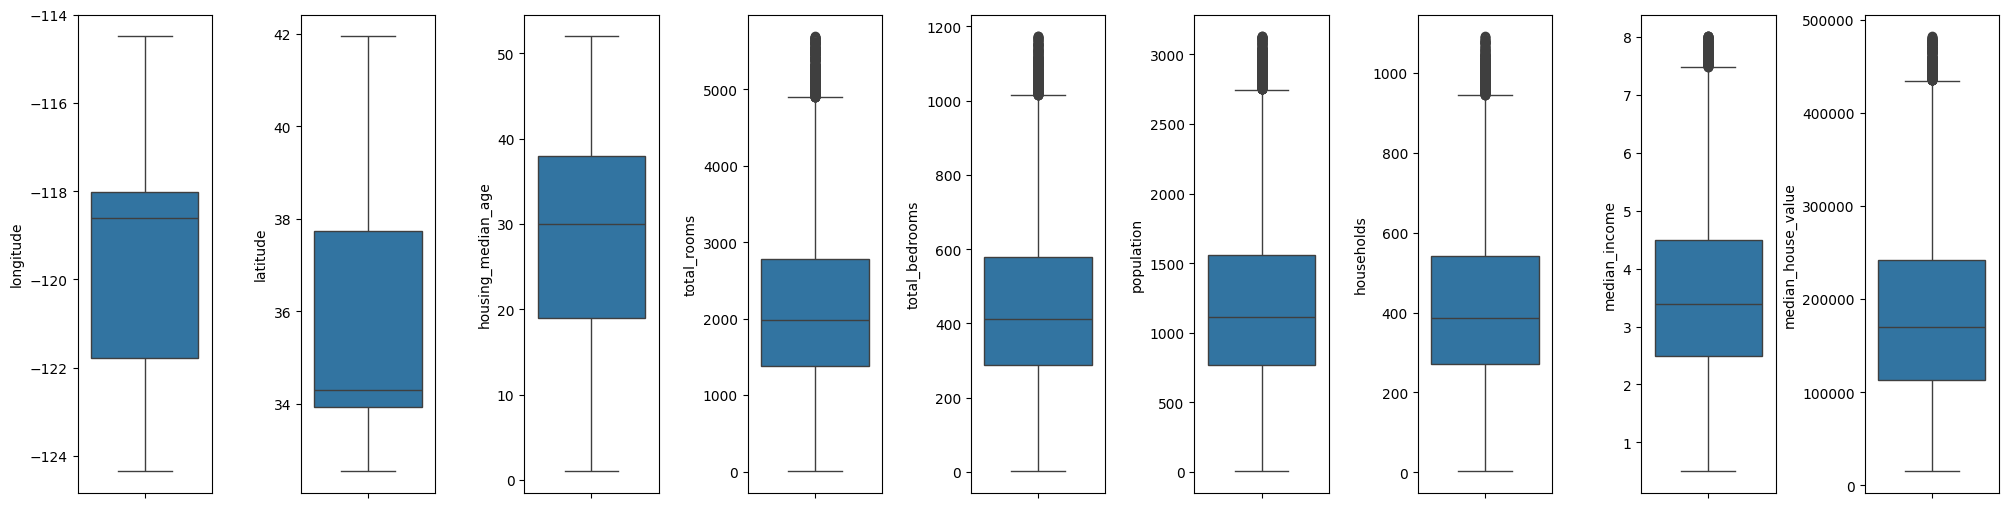

In [37]:
numeric_columns = clean_data.select_dtypes(include=['int', 'float']).columns

fig, axs = plt.subplots(ncols=len(numeric_columns), figsize=(20,5))
for i, column in enumerate(numeric_columns):
    sns.boxplot(y=column, data=clean_data, ax=axs[i], whis=1.5)

plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)
plt.show()

In [ ]:
### Isolation Forest 

""" 
- ambil fitur secara acak dan nilai yang di split secara acak 
- datanya dipecah seperti decision tree
- hitung kedalaman
"""

from sklearn.ensemble import IsolationForest 

iso = IsolationForest(contamination=0.05) # contamination -> mengasumsikan 5% data adalah outlier, model dipaksa untuk memilih 5% data sebagai outlier, walapun bisa lebih banyak atau sedikit
outliers_iso = iso.fit_predict(data[numeric_columns])

data_iso = data[outliers_iso == -1]
data_iso

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
89,-122.27,37.80,52.0,249.0,78.0,396.0,85.0,1.2434,500001.0,NEAR BAY
95,-122.26,37.80,36.0,5329.0,2477.0,3469.0,2323.0,2.0096,130000.0,NEAR BAY
101,-122.25,37.81,28.0,5806.0,1603.0,2563.0,1497.0,3.2177,273400.0,NEAR BAY
104,-122.26,37.81,34.0,5871.0,1914.0,2689.0,1789.0,2.8406,335700.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20539,-121.71,38.56,20.0,8627.0,1516.0,4071.0,1466.0,4.2198,164100.0,INLAND
20543,-121.74,38.55,33.0,6861.0,1820.0,3717.0,1767.0,1.7311,182600.0,INLAND
20544,-121.76,38.55,23.0,8800.0,1857.0,6330.0,1832.0,2.0650,219400.0,INLAND
20563,-121.75,38.67,9.0,12139.0,2640.0,6837.0,2358.0,3.1250,132500.0,INLAND


In [ ]:
# LocalOutlierFactor 

""" 
- cari tetangga terdekat 
- hitung jarak ke tetangga, semakin jauh -> semakin aneh
- hitung density (kepadatan), rapat -> normal kalau renggang -> mencurigakan
- bandingkan dengan tetangga
"""

from sklearn.neighbors import LocalOutlierFactor 

lof = LocalOutlierFactor(n_neighbors=20)
outliers_lof = lof.fit_predict(data[numeric_columns].fillna(0))

data_lof = data[outliers_lof == -1]
data_lof

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
89,-122.27,37.80,52.0,249.0,78.0,396.0,85.0,1.2434,500001.0,NEAR BAY
283,-122.16,37.79,22.0,12842.0,2048.0,4985.0,1967.0,5.9849,371000.0,NEAR BAY
458,-122.25,37.87,52.0,1204.0,460.0,2016.0,477.0,0.9490,350000.0,NEAR BAY
459,-122.25,37.87,52.0,609.0,236.0,1349.0,250.0,1.1696,500001.0,NEAR BAY
460,-122.26,37.87,52.0,1087.0,371.0,3337.0,350.0,1.4012,175000.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20527,-121.79,38.54,7.0,1777.0,513.0,4479.0,504.0,1.4653,310000.0,INLAND
20529,-121.78,38.55,12.0,10509.0,2186.0,5633.0,2138.0,2.9605,204300.0,INLAND
20530,-121.76,38.57,11.0,15018.0,3008.0,7984.0,2962.0,3.1371,201800.0,INLAND
20533,-121.67,38.54,13.0,6141.0,1019.0,2553.0,967.0,4.2432,326500.0,INLAND


In [ ]:
### Transformasi data jika skew 

data['total_rooms_log'] = np.log1p(data['total_rooms']) # log1p itu aman jika ada nilai 0, tujuan dari kode ini adalah mengurangi skew 

col = 'total_rooms_log'

Q1 = data[col].quantile(0.25)
Q3 = data[col].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_mask = (data[col] < lower) | (data[col] > upper)

outlier_rows = data[outlier_mask]
outlier_rows

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,total_rooms_log
59,-122.29,37.82,2.0,158.0,43.0,94.0,57.0,2.5625,60000.0,NEAR BAY,5.068904
61,-122.29,37.82,49.0,135.0,29.0,86.0,23.0,6.1183,75000.0,NEAR BAY,4.912655
73,-122.29,37.81,46.0,12.0,4.0,18.0,7.0,0.4999,67500.0,NEAR BAY,2.564949
81,-122.27,37.81,52.0,210.0,56.0,183.0,56.0,1.1667,112500.0,NEAR BAY,5.351858
82,-122.28,37.81,52.0,340.0,97.0,200.0,87.0,1.5208,112500.0,NEAR BAY,5.831882
...,...,...,...,...,...,...,...,...,...,...,...
20583,-122.00,38.73,31.0,371.0,74.0,208.0,84.0,3.8750,137500.0,INLAND,5.918894
20601,-121.57,39.13,30.0,442.0,103.0,413.0,88.0,1.5694,57900.0,INLAND,6.093570
20620,-121.48,39.05,40.0,198.0,41.0,151.0,48.0,4.5625,100000.0,INLAND,5.293305
20625,-121.52,39.12,37.0,102.0,17.0,29.0,14.0,4.1250,72000.0,INLAND,4.634729


### Capping

In [ ]:
data[numeric_columns] = data[numeric_columns].clip(lower=lower, upper=upper, axis=1)
data[numeric_columns].describe()